# PRCP-1016 – Heart Disease Prediction
## Complete Data Analysis and Machine Learning Notebook

**Domain:** Healthcare  
**Tasks:** Data analysis, model building/comparison, hospital recommendations, and challenge report.

### Setup
Download the ZIP file from the project brief, extract it into this notebook's folder, and keep `values.csv` and `labels.csv` beside this notebook. If your ZIP has different filenames, update the loading cell.



## 1. Import libraries

In [2]:
import os, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, ConfusionMatrixDisplay)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## 2. Load dataset
The project data may be supplied as separate feature (`values.csv`) and outcome (`labels.csv`) files. Join by `patient_id` when possible.

In [6]:
if os.path.exists("values.csv") and os.path.exists("labels.csv"):
    values = pd.read_csv("values.csv")
    labels = pd.read_csv("labels.csv")
    if "patient_id" in values.columns and "patient_id" in labels.columns:
        df = values.merge(labels, on="patient_id", how="inner")
    else:
        if len(values) != len(labels):
            raise ValueError("values.csv and labels.csv have different row counts.")
        df = pd.concat([values.reset_index(drop=True), labels.reset_index(drop=True)], axis=1)
elif os.path.exists("heart_disease.csv"):
    df = pd.read_csv("heart_disease.csv")
else:
    raise FileNotFoundError("Put values.csv and labels.csv (or heart_disease.csv) in this folder.")

print("Shape:", df.shape)
display(df.head())

Shape: (180, 15)


,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
0,0z64un,1,normal,128,2,0,0,2,308,0.0,1,45,170,0,0
1,ryoo3j,2,normal,110,3,0,0,0,214,1.6,0,54,158,0,0
2,yt1s1x,1,normal,125,4,3,0,2,304,0.0,1,77,162,1,1
3,l2xjde,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0,1
4,oyt4ek,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0,0


## 3. Inspect data and identify target

In [7]:
print(df.columns.tolist())
df.info()
display(df.describe(include="all").T)

target_candidates = ["target", "label", "heart_disease", "heartdisease",
                     "heart_disease_present", "diagnosis", "class", "output"]
TARGET_COLUMN = next((c for c in df.columns if c.lower().strip() in target_candidates), None)

# If automatic detection fails, replace None with the exact outcome column name.
if TARGET_COLUMN is None:
    raise ValueError("Target not detected. Inspect df.columns and set TARGET_COLUMN manually.")

print("Target column:", TARGET_COLUMN)
display(df[TARGET_COLUMN].value_counts(dropna=False))

['patient_id', 'slope_of_peak_exercise_st_segment', 'thal', 'resting_blood_pressure', 'chest_pain_type', 'num_major_vessels', 'fasting_blood_sugar_gt_120_mg_per_dl', 'resting_ekg_results', 'serum_cholesterol_mg_per_dl', 'oldpeak_eq_st_depression', 'sex', 'age', 'max_heart_rate_achieved', 'exercise_induced_angina', 'heart_disease_present']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 15 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   patient_id                            180 non-null    object 
 1   slope_of_peak_exercise_st_segment     180 non-null    int64  
 2   thal                                  180 non-null    object 
 3   resting_blood_pressure                180 non-null    int64  
 4   chest_pain_type                       180 non-null    int64  
 5   num_major_vessels                     180 non-null    int64  
 6   fasting_blood

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
patient_id,180,180,0z64un,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
slope_of_peak_exercise_st_segment,180.0,NaN,NaN,NaN,1.55,0.618838,1.0,1.0,1.0,2.0,3.0
thal,180,3,normal,98,NaN,NaN,NaN,NaN,NaN,NaN,NaN
resting_blood_pressure,180.0,NaN,NaN,NaN,131.311111,17.010443,94.0,120.0,130.0,140.0,180.0
chest_pain_type,180.0,NaN,NaN,NaN,3.155556,0.938454,1.0,3.0,3.0,4.0,4.0
num_major_vessels,180.0,NaN,NaN,NaN,0.694444,0.969347,0.0,0.0,0.0,1.0,3.0
fasting_blood_sugar_gt_120_mg_per_dl,180.0,NaN,NaN,NaN,0.161111,0.368659,0.0,0.0,0.0,0.0,1.0
resting_ekg_results,180.0,NaN,NaN,NaN,1.05,0.998742,0.0,0.0,2.0,2.0,2.0
serum_cholesterol_mg_per_dl,180.0,NaN,NaN,NaN,249.211111,52.717969,126.0,213.75,245.5,281.25,564.0
oldpeak_eq_st_depression,180.0,NaN,NaN,NaN,1.01,1.121357,0.0,0.0,0.8,1.6,6.2


Target column: heart_disease_present


heart_disease_present
0    100
1     80
Name: count, dtype: int64

## 4. Data quality checks

In [8]:
print("Missing values:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))
print("Duplicate rows:", df.duplicated().sum())
if "patient_id" in df.columns:
    print("Duplicate patient IDs:", df["patient_id"].duplicated().sum())

df = df.drop_duplicates().dropna(subset=[TARGET_COLUMN]).copy()
print("Cleaned shape:", df.shape)

Missing values:


,missing_count
patient_id,0
slope_of_peak_exercise_st_segment,0
thal,0
resting_blood_pressure,0
chest_pain_type,0
num_major_vessels,0
fasting_blood_sugar_gt_120_mg_per_dl,0
resting_ekg_results,0
serum_cholesterol_mg_per_dl,0
oldpeak_eq_st_depression,0


Duplicate rows: 0
Duplicate patient IDs: 0
Cleaned shape: (180, 15)


## 5. Exploratory data analysis

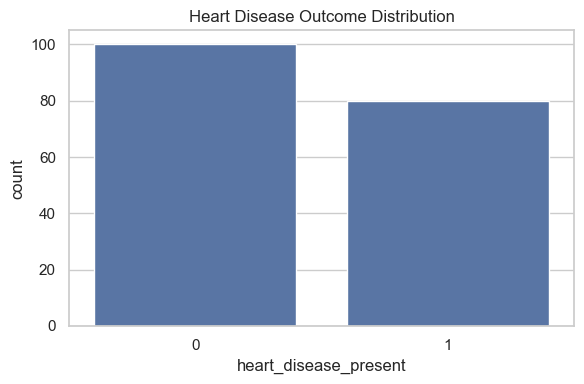

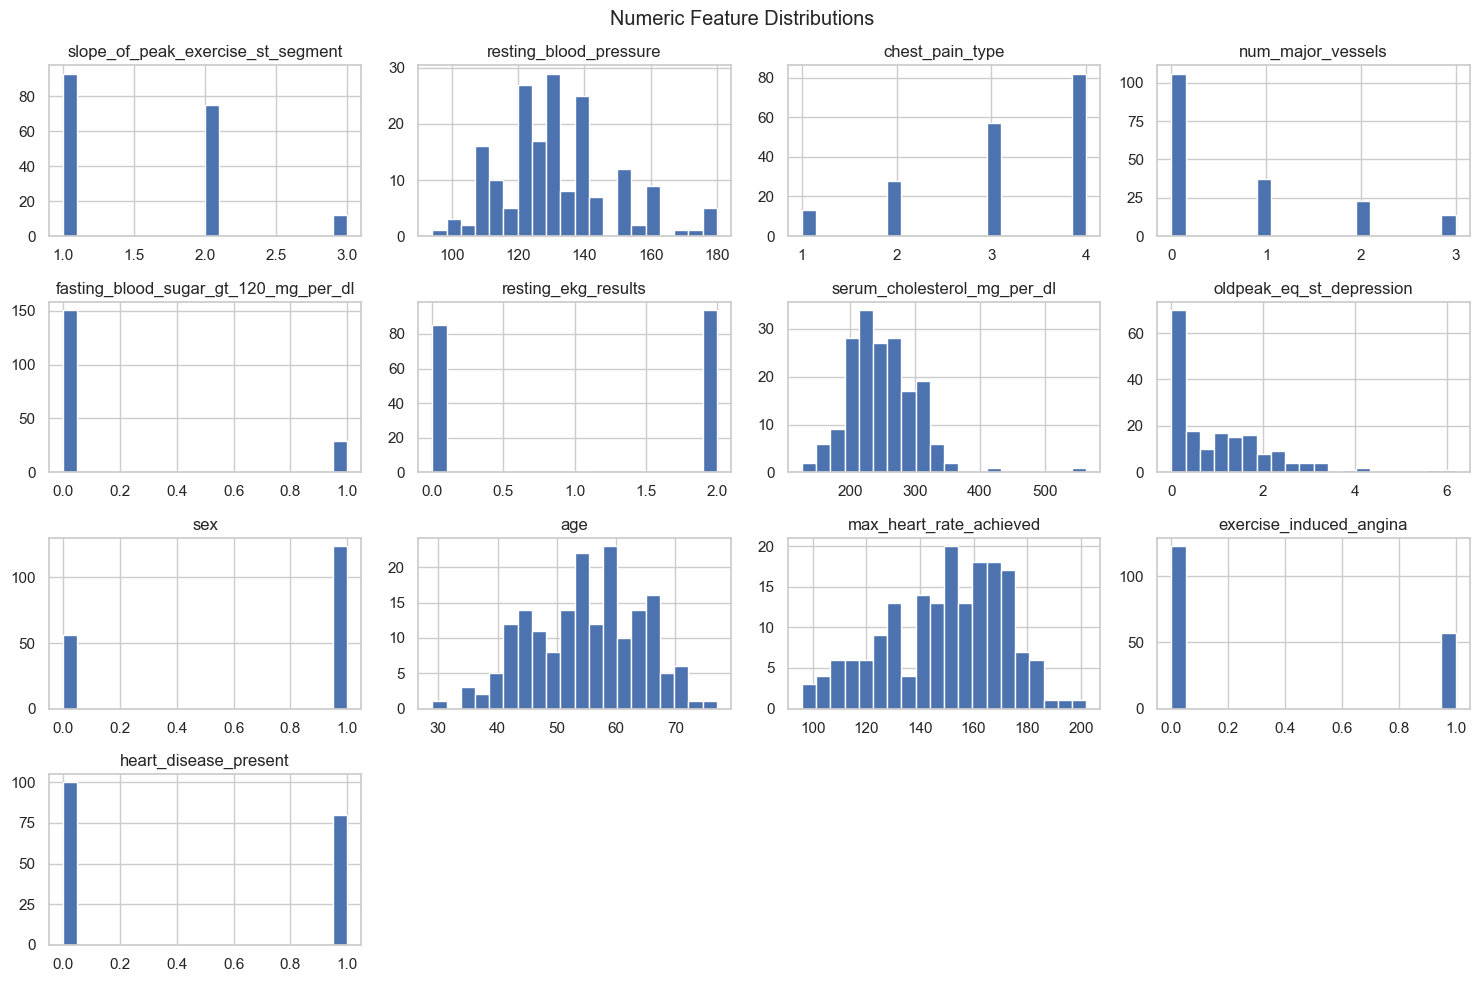

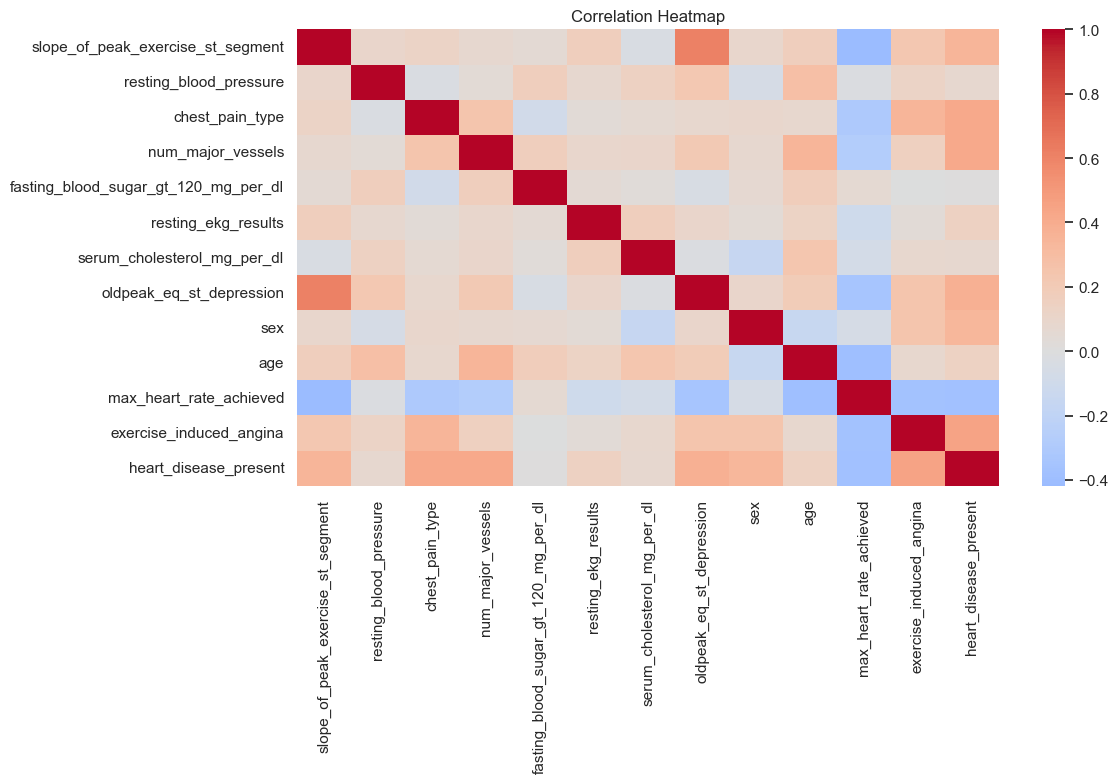

In [9]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x=TARGET_COLUMN)
plt.title("Heart Disease Outcome Distribution")
plt.tight_layout()
plt.show()

num_cols = df.select_dtypes(include=np.number).columns.tolist()
if num_cols:
    df[num_cols].hist(figsize=(15,10), bins=20)
    plt.suptitle("Numeric Feature Distributions")
    plt.tight_layout()
    plt.show()

if len(num_cols) > 1:
    plt.figure(figsize=(12,8))
    sns.heatmap(df[num_cols].corr(), cmap="coolwarm", center=0)
    plt.title("Correlation Heatmap")
    plt.tight_layout()
    plt.show()

## 6. Prepare features and target
The patient identifier is removed because it is not a clinical predictor. Imputation, scaling and categorical encoding are placed inside the pipeline to avoid data leakage.

In [10]:
X = df.drop(columns=[TARGET_COLUMN] + (["patient_id"] if "patient_id" in df.columns else [])).copy()
y = df[TARGET_COLUMN].copy()

constant_cols = [c for c in X.columns if X[c].nunique(dropna=False) <= 1]
if constant_cols:
    print("Removing constant columns:", constant_cols)
    X = X.drop(columns=constant_cols)

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_features),
    ("cat", categorical_pipe, categorical_features)
])

print("Numeric:", numeric_features)
print("Categorical:", categorical_features)
print("Target classes:", y.unique())

Numeric: ['slope_of_peak_exercise_st_segment', 'resting_blood_pressure', 'chest_pain_type', 'num_major_vessels', 'fasting_blood_sugar_gt_120_mg_per_dl', 'resting_ekg_results', 'serum_cholesterol_mg_per_dl', 'oldpeak_eq_st_depression', 'sex', 'age', 'max_heart_rate_achieved', 'exercise_induced_angina']
Categorical: ['thal']
Target classes: [0 1]


## 7. Train-test split

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, "Test:", X_test.shape)
display(y_train.value_counts(normalize=True).rename("training_proportion"))

Train: (144, 13) Test: (36, 13)


heart_disease_present
0    0.555556
1    0.444444
Name: training_proportion, dtype: float64

## 8. Train and compare multiple models
Recall is especially important in screening because false negatives may miss patients who need further assessment. Accuracy alone should not determine the preferred model.

In [12]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE,
                                             class_weight="balanced", min_samples_leaf=2),
    "Extra Trees": ExtraTreesClassifier(n_estimators=300, random_state=RANDOM_STATE,
                                        class_weight="balanced", min_samples_leaf=2),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
    "Support Vector Machine": SVC(probability=True, class_weight="balanced", random_state=RANDOM_STATE),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5)
}

rows, fitted_models = [], {}
binary = y.nunique() == 2
positive_label = sorted(y.unique())[-1] if binary else None

for name, estimator in models.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    avg = "binary" if binary else "weighted"
    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, average=avg, pos_label=positive_label if binary else 1, zero_division=0),
        "Recall": recall_score(y_test, pred, average=avg, pos_label=positive_label if binary else 1, zero_division=0),
        "F1": f1_score(y_test, pred, average=avg, pos_label=positive_label if binary else 1, zero_division=0),
        "ROC_AUC": np.nan
    }
    if binary and hasattr(pipe, "predict_proba"):
        pos_idx = list(pipe.classes_).index(positive_label)
        row["ROC_AUC"] = roc_auc_score((y_test == positive_label).astype(int),
                                       pipe.predict_proba(X_test)[:, pos_idx])
    rows.append(row)
    fitted_models[name] = pipe

comparison = pd.DataFrame(rows).sort_values(
    ["Recall", "F1", "ROC_AUC"], ascending=False
).reset_index(drop=True)
display(comparison.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Gradient Boosting,0.9167,0.8421,1.0000,0.9143,0.9562
1,Random Forest,0.8889,0.8000,1.0000,0.8889,0.9594
2,Extra Trees,0.8611,0.7895,0.9375,0.8571,0.9375
3,K-Nearest Neighbors,0.8889,0.8750,0.8750,0.8750,0.9141
4,Logistic Regression,0.8333,0.7778,0.8750,0.8235,0.9406
5,Support Vector Machine,0.8056,0.7368,0.8750,0.8000,0.9469
6,Decision Tree,0.7500,0.7333,0.6875,0.7097,0.7438


## 9. Model comparison charts

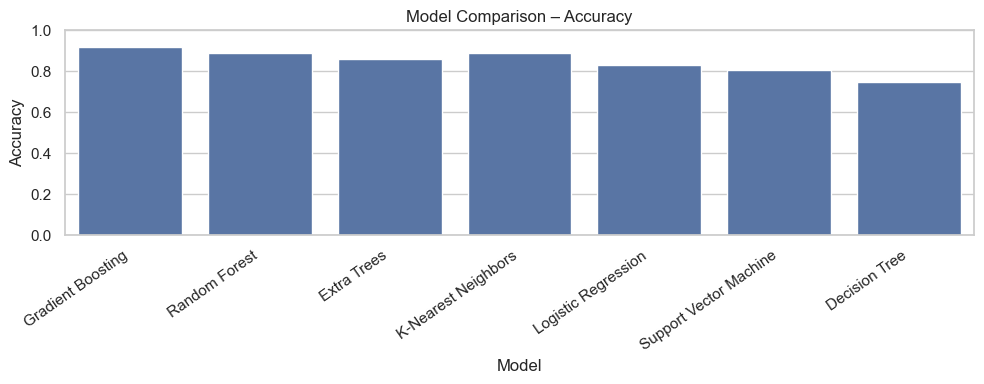

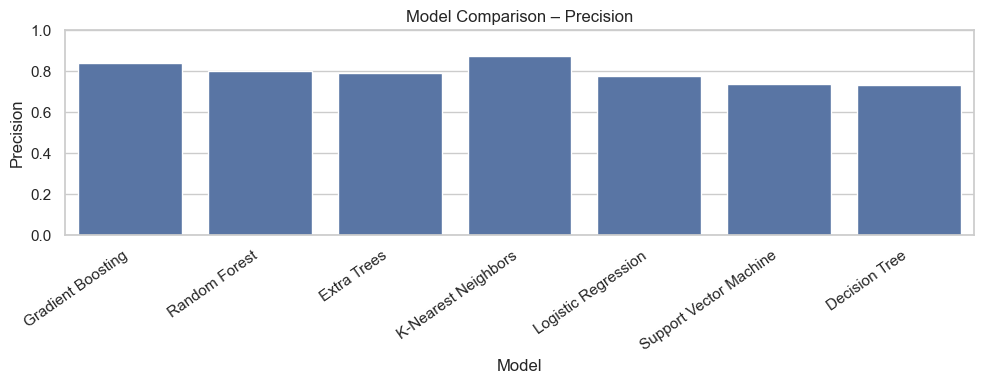

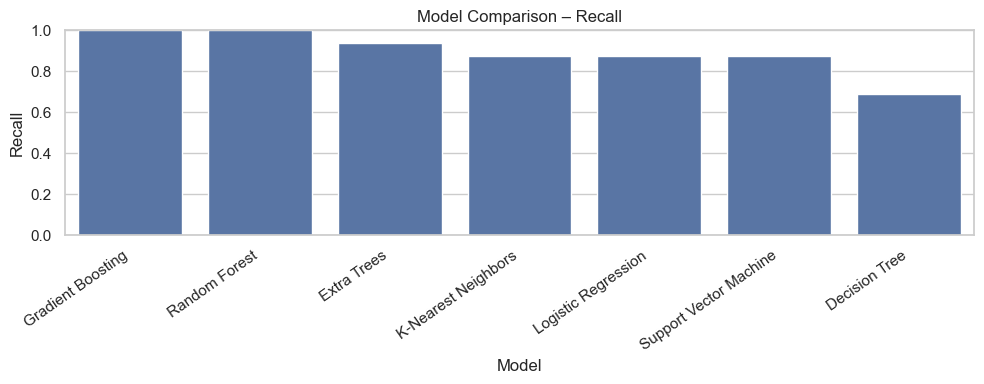

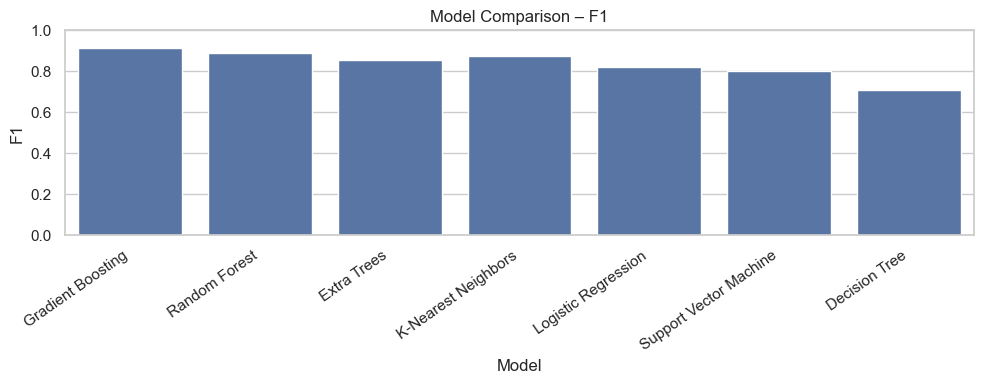

In [13]:
for metric in ["Accuracy", "Precision", "Recall", "F1"]:
    plt.figure(figsize=(10,4))
    sns.barplot(data=comparison, x="Model", y=metric)
    plt.title("Model Comparison – " + metric)
    plt.xticks(rotation=35, ha="right")
    plt.ylim(0,1)
    plt.tight_layout()
    plt.show()

## 10. Evaluate the candidate model
The candidate is ranked by test recall, then F1. This is a project-level selection rule, not a clinical deployment decision.

Candidate model: Gradient Boosting
              precision    recall  f1-score   support

           0       1.00      0.85      0.92        20
           1       0.84      1.00      0.91        16

    accuracy                           0.92        36
   macro avg       0.92      0.93      0.92        36
weighted avg       0.93      0.92      0.92        36



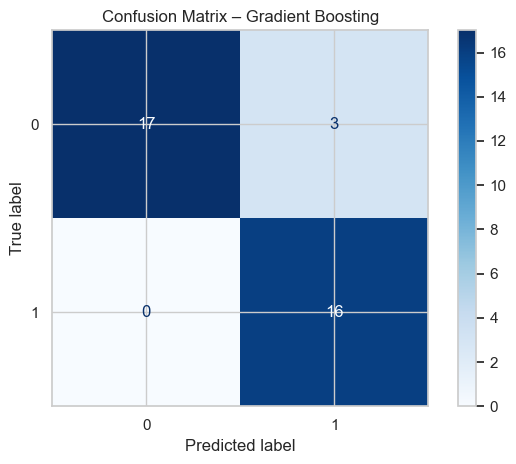

In [14]:
best_model_name = comparison.iloc[0]["Model"]
best_model = fitted_models[best_model_name]
best_pred = best_model.predict(X_test)

print("Candidate model:", best_model_name)
print(classification_report(y_test, best_pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, best_pred, cmap="Blues")
plt.title("Confusion Matrix – " + best_model_name)
plt.tight_layout()
plt.show()

## 11. Cross-validation

In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scores = cross_validate(best_model, X, y, cv=cv,
                        scoring=["accuracy", "precision", "recall", "f1"],
                        n_jobs=-1)
cv_report = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1"],
    "Mean": [scores["test_accuracy"].mean(), scores["test_precision"].mean(),
             scores["test_recall"].mean(), scores["test_f1"].mean()],
    "Standard Deviation": [scores["test_accuracy"].std(), scores["test_precision"].std(),
                           scores["test_recall"].std(), scores["test_f1"].std()]
})
display(cv_report.round(4))

,Metric,Mean,Standard Deviation
0,Accuracy,0.7722,0.0774
1,Precision,0.7627,0.1072
2,Recall,0.7375,0.1212
3,F1,0.7405,0.0829


## 12. Suggestions to hospitals

1. Use the model only as a decision-support screening aid; a qualified clinician must make clinical decisions.
2. For screening, consider sensitivity/recall carefully so that potential cases are not missed. Balance this against false positives and available clinical capacity.
3. Do not use a low-risk prediction to rule out disease when symptoms or clinical judgment indicate further assessment.
4. Validate the model using independent data from the hospital's own patient population before considering any operational use.
5. Check performance across age and sex groups and investigate differences in false-negative rates.
6. Monitor missing data, prediction calibration and changes in patient populations over time.
7. Protect patient information through secure storage, access controls and appropriate de-identification.
8. Establish a clear clinical review and referral pathway for patients flagged as potentially high risk.

## 13. Challenges faced and techniques used

In [16]:
challenges = pd.DataFrame([
    ["Separate feature and label files", "Outcome may be stored separately from predictor data.",
     "Join by patient_id; otherwise verify row counts before aligning rows."],
    ["Patient identifier", "An ID is not a meaningful clinical measurement and may cause leakage.",
     "Exclude patient_id from predictors."],
    ["Missing values", "Some fields may be incomplete.",
     "Median imputation for numeric data and most-frequent imputation for categorical data."],
    ["Categorical text values", "Fields such as thal may contain text and cannot be scaled directly.",
     "OneHotEncoder with handle_unknown='ignore'."],
    ["Different feature scales", "Measurements use different units and ranges.",
     "StandardScaler for numeric predictors."],
    ["Class imbalance", "Positive and negative outcomes may not be equally represented.",
     "Stratified split, class weights where supported, and recall/F1 reporting."],
    ["Data leakage", "Preprocessing before splitting can expose test information to training.",
     "Keep preprocessing inside an sklearn Pipeline."],
    ["Model selection", "Accuracy can hide false negatives.",
     "Compare precision, recall, F1 and ROC-AUC where applicable."],
    ["Real-world generalization", "A test split does not prove performance in another hospital.",
     "Recommend external validation, calibration and ongoing monitoring."]
], columns=["Challenge", "Why it matters", "Technique and reason"])
display(challenges)

,Challenge,Why it matters,Technique and reason
0,Separate feature and label files,Outcome may be stored separately from predicto...,Join by patient_id; otherwise verify row count...
1,Patient identifier,An ID is not a meaningful clinical measurement...,Exclude patient_id from predictors.
2,Missing values,Some fields may be incomplete.,Median imputation for numeric data and most-fr...
3,Categorical text values,Fields such as thal may contain text and canno...,OneHotEncoder with handle_unknown='ignore'.
4,Different feature scales,Measurements use different units and ranges.,StandardScaler for numeric predictors.
5,Class imbalance,Positive and negative outcomes may not be equa...,"Stratified split, class weights where supporte..."
6,Data leakage,Preprocessing before splitting can expose test...,Keep preprocessing inside an sklearn Pipeline.
7,Model selection,Accuracy can hide false negatives.,"Compare precision, recall, F1 and ROC-AUC wher..."
8,Real-world generalization,A test split does not prove performance in ano...,"Recommend external validation, calibration and..."


## 14. Final project report summary

In [17]:
print("PROJECT: PRCP-1016 – HEART DISEASE PREDICTION")
print("=" * 60)
print("Records analyzed:", len(df))
print("Predictor count:", X.shape[1])
print("Target column:", TARGET_COLUMN)
print("Candidate model (ranked by recall/F1):", best_model_name)
display(comparison.round(4))
display(cv_report.round(4))

PROJECT: PRCP-1016 – HEART DISEASE PREDICTION
Records analyzed: 180
Predictor count: 13
Target column: heart_disease_present
Candidate model (ranked by recall/F1): Gradient Boosting


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Gradient Boosting,0.9167,0.8421,1.0000,0.9143,0.9562
1,Random Forest,0.8889,0.8000,1.0000,0.8889,0.9594
2,Extra Trees,0.8611,0.7895,0.9375,0.8571,0.9375
3,K-Nearest Neighbors,0.8889,0.8750,0.8750,0.8750,0.9141
4,Logistic Regression,0.8333,0.7778,0.8750,0.8235,0.9406
5,Support Vector Machine,0.8056,0.7368,0.8750,0.8000,0.9469
6,Decision Tree,0.7500,0.7333,0.6875,0.7097,0.7438


,Metric,Mean,Standard Deviation
0,Accuracy,0.7722,0.0774
1,Precision,0.7627,0.1072
2,Recall,0.7375,0.1212
3,F1,0.7405,0.0829


## 15. Conclusion
This project performs data quality checks, exploratory analysis, preprocessing, training and comparison of multiple classification algorithms. The candidate model is ranked using recall and F1-score in addition to accuracy. The results are estimates from this dataset and do not establish clinical safety.

### Submission checklist
- [ ] Extract the supplied ZIP and place CSV files beside this notebook.
- [ ] Run all cells from top to bottom.
- [ ] Confirm that `TARGET_COLUMN` is the actual outcome label.
- [ ] Review the model comparison and cross-validation results.
- [ ] Save the notebook with outputs for submission.
- [ ] Do not describe the model as production-ready based only on this experiment.

